# A* Grid Planning

Find a shortest route across a four-connected occupancy grid and count how much of the grid each search expands.

Every step costs one. Manhattan distance is a consistent lower bound on the remaining cost on this grid. A* expands a node of least accumulated cost plus heuristic. Dijkstra uses the same queue discipline with the heuristic set to zero. Both should return the same optimal length.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from planning import grid_search

## Search the floor plan

Compare against the separate SciPy graph shortest-path routine, including a test in which the goal is isolated.

Optimal distance 62 cells | expanded by A*: 510, by Dijkstra: 627


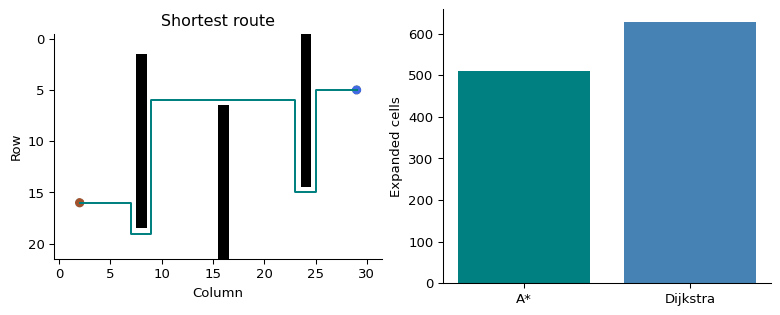

In [2]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path

grid = np.zeros((22, 32), bool)
grid[2:19, 8] = True
grid[7:, 16] = True
grid[:15, 24] = True
start = (16, 2)
goal = (5, 29)
path, n = grid_search(grid, start, goal)
other, m = grid_search(grid, start, goal, lambda a, b: 0)
indices = np.arange(grid.size).reshape(grid.shape)
edges = []
for a, b in [(indices[:, :-1], indices[:, 1:]), (indices[:-1, :], indices[1:, :])]:
    keep = ~grid.ravel()[a] & ~grid.ravel()[b]
    edges.extend(zip(a[keep], b[keep]))
r, c = zip(*edges)
graph = csr_matrix((np.ones(len(r)), (r, c)), shape=(grid.size, grid.size))
distance = shortest_path(graph, directed=False, indices=indices[start], unweighted=True)[
    indices[goal]
]
assert len(path) - 1 == len(other) - 1 == distance
barrier = grid.copy()
barrier[:, 14] = True
assert not grid_search(barrier, start, goal)[0]
print(f"Optimal distance {int(distance)} cells | expanded by A*: {n}, by Dijkstra: {m}")
fig, (a, b) = plt.subplots(1, 2, figsize=(8.1, 3.2), constrained_layout=True)
a.imshow(grid, cmap="Greys", vmin=0, vmax=1)
y, x = np.array(path).T
a.plot(x, y, color="teal")
a.scatter([start[1], goal[1]], [start[0], goal[0]], color=["sienna", "royalblue"])
a.set(title="Shortest route", xlabel="Column", ylabel="Row")
b.bar(["A*", "Dijkstra"], [n, m], color=["teal", "steelblue"])
b.set(ylabel="Expanded cells")
plt.show()

## Interpreting the result

Expansion counts depend on queue tie-breaking. Agreement with the independent shortest-path distance tests optimality on this instance.

## Exercise

Change to eight-connected motion and derive an admissible heuristic for the new step costs.

## References

[Hart, Nilsson and Raphael, A Formal Basis for the Heuristic Determination of Minimum Cost Paths](https://doi.org/10.1109/TSSC.1968.300136)

[SciPy graph shortest paths](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csgraph.shortest_path.html)